# Семинар по теме «Деревья регрессии»

Дерево решений – это алгоритм машинного обучения, который использует структуру дерева для принятия решений. В контексте регрессии дерево решений разбивает пространство признаков на области и в каждой области предсказывает постоянное значение целевой переменной. При обучении дерево рекурсивно разделяет данные на подмножества. На каждом узле выбирается признак и пороговое значение, которые лучше всего разделяют данные, так целевая переменная будет однородной в узлах (листьях) дерева.

Из этого семинара ты узнаешь:

- как обучить дерево решений для задач регрессии без ограничений;
- как оценить качество дерева регрессии (train/test) и визуализировать его;
- как использовать Optuna для подбора оптимальных гиперпараметров дерева;
- как стричь дерево для борьбы с переобучением;
- как работает feature importance (важность признаков) в деревьях;
- чем отличается дерево решений от линейной регрессии.

В каждом разделе ты напишешь свой код по реализации одной из функций деревьев.

## Краткая теория

Когда мы строим дерево, мы на каждом шаге подбираем такой сплит региона, который уменьшит меру неопределённости модели и как можно точнее сгруппирует данные на два получившихся региона. А для каждого итогового региона подбираем константное предсказание. В случае регрессии это обычно среднее арифметическое.

Разберём, как это выглядит с точки зрения математики.

В рамках жадного рекурсивного бинарного разбиения на каждом разбиении дерева регрессии/классификации максимизируем функционал качества:

$$
Q(R, j, t) = H(R) - \left (\frac{|R_\ell|}{|R|} H(R_\ell) + \frac{|R_r|}{|R|} H(R_r)\right),
$$

подобрав оптимальные параметры на текущем сплите:

$$
(j, t) = argmax_{j, t} \ Q(R, j, t).
$$




Мера неопределённости региона показывает, насколько объекты внутри региона «не похожи друг на друга»:

$$
H(R) = \min_{c \in Y} \frac{1}{|R|} \sum_{(x_i, y_i) \in R} L(y_i, c),
$$

где $c$ — наше константное предсказание, вещественное число в случае регрессии.

Самый применяемый функционал ошибки в задачах регрессии — квадратичная ошибка:

$$
L(y_i, c) = (y_i - c)^2.
$$

Если константное предсказание — среднее арифметическое, неопределённость внутри региона измеряется среднеквадратичной ошибкой (Mean Squared Error, MSE):

$$
H(R) = \frac{1}{|R|} \sum_{(x_i, y_i) \in R} (y_i - \bar{y})^2.
$$




При обучении дерева на каждом шаге нам нужно подбирать такой сплит (признак и порог), который минимизирует общую среднеквадратичную ошибку модели.

На тренировочных данных при достаточно глубоком дереве в какой-то момент  среднеквадратичная ошибка станет нулевой, и дерево полностью запомнит обучающую выборку. Но это не всегда хорошо.

## Данные

Этап работы с данными разделим на две части:
- проведём разведочный анализ данных (EDA), чтобы изучить распределение данных, пропущенные значения и провести корреляционный анализ;

- по результатам РАД увидим все проблемы. Затем проведём препроцессинг данных и подготовим данные для обучения в модели деревьев.

Сегодня используем дерево решений для задачи регрессии на примере Communities and Crimes. Это датасет со статистикой по городам США: демографические, экономические показатели и уровень насильственных преступлений. Целевая переменная `ViolentCrimesPerPop` – число насильственных преступлений на душу населения. Модель дерева решений должна научиться предсказывать эту переменную по совокупности остальных признаков.

## Разведочный анализ данных (EDA)

Начнём с загрузки данных и их первичного анализа. Воспользуемся датасетом Communities and Crimes. В этом наборе данных целевой признак ($y$) — уровень насильственной преступности (`ViolentCrimesPerPop`), а остальные колонки ($X$) — различные статистические показатели по сообществам.


Выполним загрузку датасета и посмотрим на его структуру: количество образцов, признаков, примеры значений.

In [1]:
!pip install ucimlrepo --quiet

In [2]:
# Импорт библиотек
from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

In [3]:
# Загрузка данных
communities_and_crime = fetch_ucirepo(id=183)
X = communities_and_crime.data.features
y = communities_and_crime.data.targets
X.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,8,?,?,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14
1,53,?,?,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,?,0.02,0.12,0.45,?,?,?,?,0.00,?
2,24,?,?,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,?,0.01,0.21,0.02,?,?,?,?,0.00,?
3,34,5,81440,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,?,0.02,0.39,0.28,?,?,?,?,0.00,?
4,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,?,0.04,0.09,0.02,?,?,?,?,0.00,?


Рассмотрим основные признаки датасета.

1. **Идентификаторы сообщества** (неинформативны, могут быть удалены)

    1.1. `state` (код или номер штата)  
    1.2. `county` (код округа)  
    1.3. `community` (числовой идентификатор сообщества)  
    1.4. `communityname` (название сообщества)  
    1.5. `fold` (номер фолда для кросс-валидации)

2. **Демографические и социально-экономические признаки**

    2.1. `population` (общая численность)  
    2.2. `populationdensity` (плотность населения)  
    2.3. `PctUrban` (% городского населения)  
    2.4. `householdsize` (средний размер домохозяйства)  
    2.5. `PctFam2Par` (доля семей с двумя родителями)  
    2.6. `PctKids2Par`, `PctYoungKids2Par`, `PctTeen2Par` (доли детей и подростков в семьях с двумя родителями)     
    2.7. `PctUnemployed` (уровень безработицы)    
    2.8. `PctPopUnder18`, `PctPop65Older` (доля населения младше 18 лет или старше 65 лет)  
    2.9. `racePctWhite`, `racePctBlack`, `racePctAsian`, `racePctHisp` (доля белокожего, чернокожего, азиатского, латиноамериканского населения)  
    > _И другие схожие демографические/социоэкономические признаки._

3. **Признаки правоохранительных органов**

    3.1. `PolicPerPop` (число полицейских на 100 000 человек)  
    3.2. `PolicBudgPerPop` (бюджет полиции на 100 000)  
    3.3. `PctPolicOnPatr` (% офицеров на патруле)    
    > _И другие признаки, связанные с ресурсами/структурой полиции._

4. **Показатели преступности**  
    4.1. `ViolentCrimesPerPop` (тяжкие преступления на 100 000 человек) — целевая переменная

    4.2. `nonViolPerPop` (ненасильственные преступления на 100 000)  
    4.3. `murdersPerPop` (убийства на 100 000)  
    4.4. `rapePerPop` (изнасилования на 100 000)  
    4.5. `robberyPerPop` (грабежи на 100 000)  
    4.6. `assaultPerPop` (нападения на 100 000)  
    4.7. `burglaryPerPop` (кражи со взломом на 100 000)   
    4.8. `autoTheftPerPop` (угон автомобилей на 100 000)  
    > _И другие виды преступлений._




Все числовые признаки в этом датасете нормированы в диапазон [0, 1] равными интервалами. Хотя для анализа деревьев решений это не нужно: деревья нечувствительны к масштабу признаков.

Теперь посмотрим на структуру данных и их распределение.

Для удобства заменим все неизвестные значения (`?`) на `NaN`.

In [4]:
X = X.replace("?", np.nan)
X.head(3)

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN


In [5]:
# Быстрый обзор: сколько строк/столбцов, типы данных
print("X Shape:", X.shape)
X.info()
print('-' * 50)
print('-' * 50)
print("Y Shape:", y.shape)
y.info()

X Shape: (1994, 127)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1994 entries, 0 to 1993
Columns: 127 entries, state to PolicBudgPerPop
dtypes: float64(99), int64(2), object(26)
memory usage: 1.9+ MB
--------------------------------------------------
--------------------------------------------------
Y Shape: (1994, 1)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1994 entries, 0 to 1993
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ViolentCrimesPerPop  1994 non-null   float64
dtypes: float64(1)
memory usage: 15.7 KB


В целевой переменной нет пропущенных значений (хотя в признаках есть). А в датасете есть 26 категориальных признаков (object features). Это происходит, потому что в изначальном датасете вместо `NaN` пропущенные значения обозначались как `'?'` и признаки с пропущенными значениями имеют тип данных `object`.

Теперь, когда у нас нет `'?'` значений в датасете, попробуем перевести все признаки в численный тип.

In [6]:
# Первые пять признаков не трогаем, так как они не несут ценности
for col in X.columns[5:]:
    X[col] = pd.to_numeric(X[col], errors="raise")

In [7]:
# Какие признаки остались категориальными?
X.select_dtypes(include=['object']).columns

Index(['county', 'community', 'communityname'], dtype='object')

Теперь единственные категориальные признаки — `county`, `community`, `communityname`. Это не проблема: признаки не информативны, их удаляем на этапе препроцессинга.

Посмотрим на распределение признаков в датасете.

In [8]:
X.describe()

,state,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
count,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,...,319.000000,1994.000000,1994.000000,1994.000000,319.000000,319.000000,319.000000,319.000000,1994.000000,319.000000
mean,28.683551,5.493982,0.057593,0.463395,0.179629,0.753716,0.153681,0.144022,0.424218,0.493867,...,0.305987,0.065231,0.232854,0.161685,0.163103,0.076708,0.698589,0.440439,0.094052,0.195078
std,16.397553,2.873694,0.126906,0.163717,0.253442,0.244039,0.208877,0.232492,0.155196,0.143564,...,0.226884,0.109459,0.203092,0.229055,0.214778,0.140207,0.213944,0.405808,0.240328,0.164718
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,12.000000,3.000000,0.010000,0.350000,0.020000,0.630000,0.040000,0.010000,0.340000,0.410000,...,0.140000,0.020000,0.100000,0.020000,0.040000,0.020000,0.620000,0.000000,0.000000,0.110000
50%,34.000000,5.000000,0.020000,0.440000,0.060000,0.850000,0.070000,0.040000,0.400000,0.480000,...,0.260000,0.040000,0.170000,0.070000,0.080000,0.030000,0.750000,0.500000,0.000000,0.150000
75%,42.000000,8.000000,0.050000,0.540000,0.230000,0.940000,0.170000,0.160000,0.470000,0.540000,...,0.395000,0.070000,0.280000,0.190000,0.195000,0.060000,0.840000,1.000000,0.000000,0.220000
max,56.000000,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Среди признаков есть отсутствующие значения. Посчитаем, в каких конкретно признаках есть `NaN` и какой процент от всех данных по признаку он занимает.

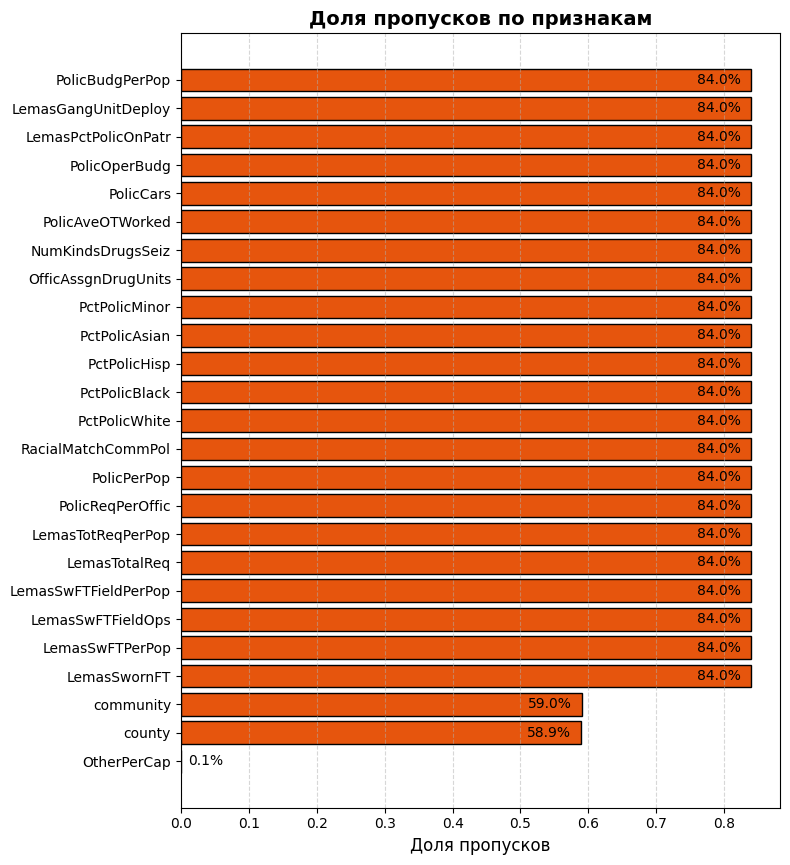

In [9]:
# Получим серию для визуализации
na_ratio = X.isnull().mean()
na_features = na_ratio[na_ratio > 0].sort_values(ascending=True)  # Снизу вверх — от меньшего к большему

plt.figure(figsize=(8, max(3, 0.35 * len(na_features))))
bars = plt.barh(na_features.index, na_features.values, color="#e6550d", edgecolor="black")

# Подписи процентов справа от столбцов
for num, bar in enumerate(bars):
    width = bar.get_width()
    if num == 0:
      plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f"{width:.1%}", va='center', fontsize=10)
    else:
      plt.text(width - 0.08, bar.get_y() + bar.get_height()/2, f"{width:.1%}", va='center', fontsize=10)

plt.xlabel("Доля пропусков", fontsize=12)
plt.title("Доля пропусков по признакам", fontsize=14, fontweight='bold')
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

На этом этапе много признаков, большая часть данных по которым недоступна (>80%). Интересно заметить, что 20 признаков с более 80% пропусков имеют пропущенные значения по тем же самым наблюдениям.

На этапе препроцессинга решаем проблему пропусков.

Посмотрим теперь на распределение целевого признака.

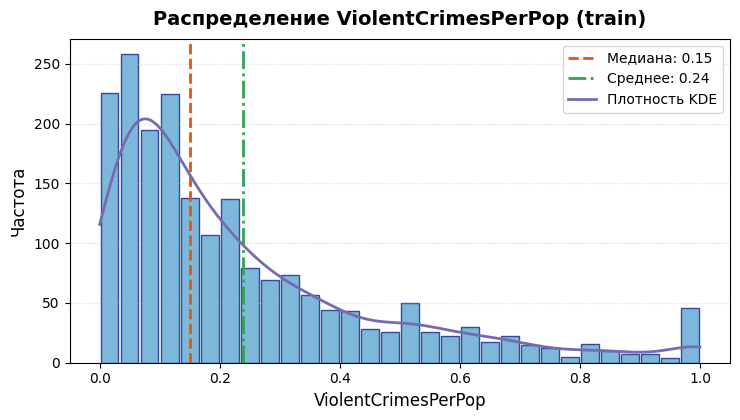

In [10]:
from scipy.stats import gaussian_kde

ycopy = np.asarray(y)

plt.figure(figsize=(7.5, 4.3))
n, bins, patches = plt.hist(
    ycopy, bins=30, color='#6baed6', edgecolor='#253494', alpha=0.88, rwidth=0.88)

# Сделаем медиану и среднее
plt.axvline(np.median(ycopy), color='#e6550d', linestyle='--', linewidth=2, label=f"Медиана: {np.median(ycopy):.2f}")
plt.axvline(np.mean(ycopy), color='#31a354', linestyle='-.', linewidth=2, label=f"Среднее: {np.mean(ycopy):.2f}")

# И даже добавим плотность
kde = gaussian_kde(ycopy.ravel())
x_kde = np.linspace(ycopy.min(), ycopy.max(), 200)
plt.plot(x_kde, kde(x_kde) * len(ycopy) * (bins[1] - bins[0]), color="#756bb1", linewidth=2, label="Плотность KDE")

plt.title('Распределение ViolentCrimesPerPop (train)', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('ViolentCrimesPerPop', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.legend(fontsize=10, frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

Найдём признаки, которые наиболее тесно связаны с целевой переменной. Это даст первое представление о факторах, связанных с уровнем преступности. Также выведем топ-10 признаков с наибольшей по модулю корреляцией с `y`.


In [11]:
# Соединим X и y вместе для удобства вычисления корреляции
df = X.iloc[:, 5:].copy()
df['target'] = y.values

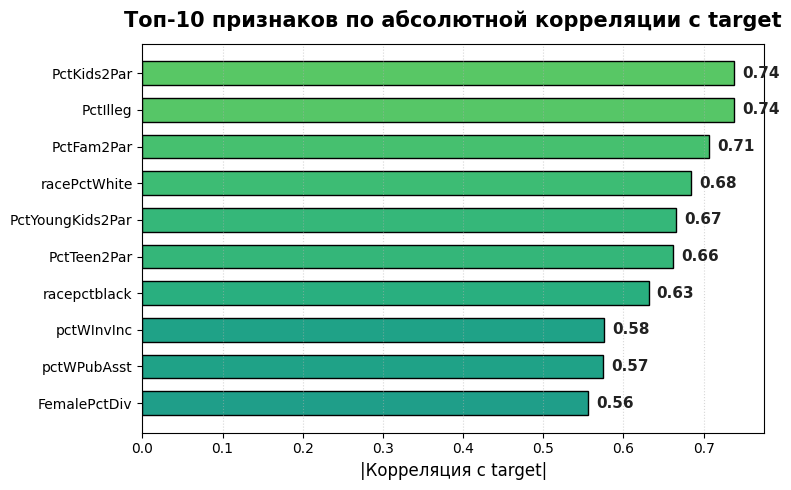

In [12]:
# Рассчитаем корреляцию
corr = df.corr()['target'].abs().sort_values(ascending=False)

top_n = 10
features = corr.index[1:top_n+1]    # [1:], чтобы не брать сам таргет
values = corr.values[1:top_n+1]

plt.figure(figsize=(8, 5))
bars = plt.barh(features[::-1], values[::-1],
                color=plt.cm.viridis(values[::-1]), edgecolor='black', height=0.65)

# Подписи справа на концах баров
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}', va='center', fontsize=11, fontweight='bold', color="#222")

plt.xlabel('|Корреляция с target|', fontsize=12)
plt.title('Топ-10 признаков по абсолютной корреляции с target',
          fontsize=15, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

Корреляционный анализ показывает, какие признаки линейно связаны с уровнем преступности. Обрати внимание: ни одного из признаков с более 80% пропусков здесь нет. Ещё одна причина удалить их из датасета.

### Препроцессинг данных

В описании набора данных указано, что некоторые признаки не информативны, например идентификаторы штата и города. Есть и пропущенные значения.

Наш следующий шаг — выполнить препроцессинг.
- Удалить неинформативные признаки: `state`, `county`, `community`, `communityname`, `fold`.
- Выбрать стратегию для работы с пропущенными значениями: удалить их или заполнить.
- Разделить данные на обучающую и тестовую выборки, чтобы оценивать качество модели на новых данных.


###Задание 1.1

Удали неинформативные столбцы из `DataFrame X`: `state`, `county`, `community`, `communityname`, `fold`. Используй для этого `pandas.DataFrame.drop`().

In [13]:
# Напиши код здесь: удаление лишних столбцов и заполнение пропусков
cols_to_drop = ['state', 'county', 'community', 'communityname', 'fold']
X = X.drop(columns=cols_to_drop)

Интересно: почти все признаки с пропусками имеют более 80% NA значений. Единственный признак с одним пропущенным значением — `OtherPerCap`.

###Задание 1.2

 Все признаки с более 80% пропусков удаляем, как неинформативные. А в численном признаке `OtherPerCap` заменим единственный пропуск на среднее арифметическое.

Примени эту схему. Убедись, что после этого в данных нет пропусков.

In [ ]:
# Один пропуск в OtherPerCap
X['OtherPerCap'].isna().sum()

In [14]:
THRESHOLD = 0.8      # 80% пропусков и больше → выкидываем признак

cols_to_drop = X.columns[X.isna().mean() >= THRESHOLD]

# Напиши код здесь
# 1. Удаляем слишком пустые признаки (используй pd.df.drop())
# X = X.drop(columns=cols_to_drop)

# 2. В OtherPerCap заполняем NaN средним (используй pd.df.fillna())
X = X.fillna({'OtherPerCap': X['OtherPerCap'].mean()})

# 3. Здесь мы убеждаемся, что все оставшиеся признаки — вещественные числа (не считая NAN значений)
X = X.apply(pd.to_numeric)

# 4. Проверим, остались ли пропуски
# print('Общее число пропущенных значений после импутации:', ...)
print(X.isna().sum().sum())

0


Посмотрим на наш датасет.

In [17]:
X.head()

,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.0,0.12,0.42,0.50,0.51,0.64,0.12,0.26,0.20,0.32
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.0,0.21,0.50,0.34,0.60,0.52,0.02,0.12,0.45,0.00
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.0,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.00
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.0,0.19,0.30,0.73,0.64,0.65,0.02,0.39,0.28,0.00
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.0,0.11,0.72,0.64,0.61,0.53,0.04,0.09,0.02,0.00


Теперь разделим набор данных на обучающую и тестовую выборки. Это необходимо для честной оценки модели: обучаем дерево на train-части, а оцениваем качество на test-части.


###Задание 1.3

Разбей данные на обучающую (train) и тестовую (test) выборки. Используй функцию `train_test_split` из `sklearn.model_selection`. Выдели 20% данных под тестовую выборку. Не забудь зафиксировать `random_state` для воспроизводимости.

In [16]:
# Напиши код здесь: разбиение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=20)

print('Размер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)

Размер обучающей выборки: (1595, 100)
Размер тестовой выборки: (399, 100)


По итогам препроцессинга мы подготовили данные для моделирования:
- удалили неинформативные столбцы,
- заполнили пропуски
- разделили выборку на обучающую и тестовую.

РАД показал распределение целевой переменной и позволил выявить признаки, которые потенциально связаны с целевым значением.

Теперь приступаем к обучению модели дерева решений.

## Неограниченные деревья

### Обучение неограниченного дерева решений

Разберём, как выглядит класс `DecisionTreeRegressor` в модуле `sklearn.tree` для обучения деревьев. А на следующем семинаре рассмотрим, как построить свой класс деревьев решений в Python.

In [ ]:
'''model = DecisionTreeRegressor(criterion='squared_error', # Критерий расщепления
                                                            # («squared_error» / «absolute_error»)
     splitter='best',               # Разбиение  «best»/«random»
     max_depth=None,                # Допустимая глубина
     min_samples_split=2,           # Минимальная выборка для разбиения
     min_samples_leaf=1,            # Минимальная мощность листа
     min_weight_fraction_leaf=0.0,  # Аналогично с весом
     max_features=None,             # Признаки для нахождения разбиения
     random_state=None,             # Чтобы можно было воспроизвести результаты
     max_leaf_nodes=None,           # Допустимое число листьев
     min_impurity_decrease=0.0,     # Порог изменения «зашумлённости»
     ccp_alpha=0.0)                 # для стрижки дерева (post-pruning)

model.fit(X, y)''';

Разберём, что делает каждый гиперпараметр.

`criterion` (`'squared_error'` / `'absolute_error'` / `other`) — функция качества разбиения, по которой оценивается «шумность» узлов (чаще всего MSE или MAE).

`splitter `(`'best'` / `'random'`) — способ выбора разбиения в узле: либо оптимальное среди всех возможных, либо случайное.

`max_depth` (`int` или `None`) — максимальная глубина дерева (сколько разбиений можно делать подряд), `None` = без ограничения.

`min_samples_split` (`int`) — минимальное число образцов в узле, необходимое, чтобы попытаться его разделить.

`min_samples_leaf` (`int`) — минимальное число образцов, которое должно оказаться в листе после разбиения.

`min_weight_fraction_leaf` (`float`) — минимальная доля от суммы весов всех образцов, которая должна приходиться на лист.

`max_features` (`int`/`float`/`str` или `None`) — число признаков, которые рассматриваются при поиске лучшего разбиения (`None` = все признаки).

`random_state` (`int`) — зерно генератора случайных чисел для воспроизводимости случайных решений.

`max_leaf_nodes` (`int` или `None`) — максимально допустимое число листьев в дереве, `None` = без ограничения.

`min_impurity_decrease` (`float`) — минимальное уменьшение показателя «неоднородности» (`impurity`), необходимое для выполнения разбиения.

`ccp_alpha` (`float`) — параметр сложности для пост-стрижки дерева (pruning) в методе cost-complexity; большее значение — более агрессивная обрезка.

В коде выше указаны дефолтные значения гиперпараметров.

Начнём с базового варианта: обучим дерево решений для регрессии без ограничения глубины (и других параметров сложности). Класс `DecisionTreeRegressor` по умолчанию не ограничивает глубину дерева. Рост продолжается, пока листья не станут полностью чистыми (целевые ответы всех наблюдений не станут одинаковыми) или пока не останется меньше двух образцов для разделения.


###Задание 2 (0.5 балла)

Обучи `DecisionTreeRegressor` (дерево решений для регрессии) на обучающих данных (`X_train`, `y_train`) с параметрами по умолчанию. Используя методы `model.get_depth()` и `model.get_n_leaves()`, выведи полученную глубину дерева и число листьев. Эти значения дадут представление о размере получившегося дерева.

In [20]:
# Напиши код здесь: обучение DecisionTreeRegressor и вывод глубины и числа листьев
tree_unlimited = DecisionTreeRegressor()
tree_unlimited.fit(X_train, y_train)

print('Глубина дерева:', tree_unlimited.get_depth())
print('Число листьев:', tree_unlimited.get_n_leaves())

Глубина дерева: 24
Число листьев: 1208


Итак, ты обучил дерево решений максимальной сложности. Глубина получилась очень большой, число листьев крайне велико. Модель разделила данные до максимально возможной точности на обучающей выборке.

**Вопрос**

Каким будет качество такого дерева на обучающих и на тестовых данных?

Ожидаешь ли ты переобучение? Если да, то почему?

### Оценка качества неограниченной модели

 Оценим качество получившегося дерева решений на обучающей и тестовой выборках. Будем использовать метрики Mean Squared Error (MSE) и коэффициент детерминации $R^2$ для количественной оценки. MSE измеряет средний квадрат ошибки прогноза, а $R^2$ показывает долю объяснённой вариативности. Значение $R^2=1$ — это идеальное предсказание.

###Задание 3

Вычисли MSE и $R^2$ на обучающем и тестовом наборах для модели `tree_unlimited`, которую обучали выше.

In [21]:
# Напиши код здесь: предсказания и вычисление метрик R2, MSE
y_train_pred = tree_unlimited.predict(X_train)
y_test_pred = tree_unlimited.predict(X_test)
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

print(f'MSE (train): {mse_train:.4f}')
print(f'MSE (test): {mse_test:.4f}')
print(f'R^2 (train): {r2_train:.4f}')
print(f'R^2 (test): {r2_test:.4f}')

MSE (train): 0.0000
MSE (test): 0.0402
R^2 (train): 1.0000
R^2 (test): 0.2702


### Визуализация дерева решений

Если наглядно представить логику принятия решений, то можно визуализировать модель деревьев решений. Но полностью визуализировать глубокое дерево может быть трудно из-за его размера. Отобразим верхние уровни дерева, чтобы увидеть, по каким признакам и порогам происходит первое ветвление.

###Задание 4 (0.5 балла)

Визуализируй обученное дерево решений `tree_unlimited` (найди в интернете, как можно нарисовать дерево). Ограничь глубину отображения несколькими уровнями (например, 2 уровня), чтобы картинка получилась читаемой. Отобрази названия признаков. Попробуй получить красивую визуализацию, поэкспериментируй с гиперпараметрами функции визуализации дерева.

Анализируя верхние разбиения, попробуй понять, какие признаки сильнее всего влияют на решение дерева.

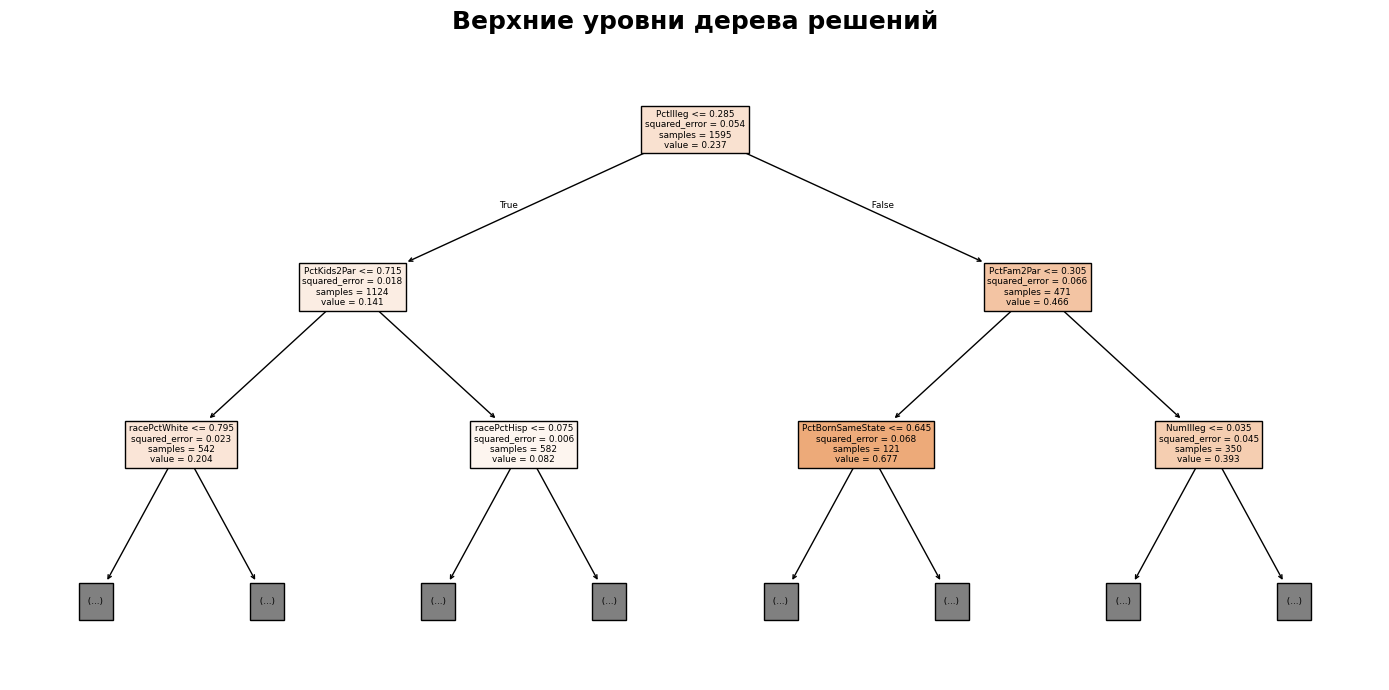

In [23]:
plt.figure(figsize=(14, 7))
tree.plot_tree(tree_unlimited, feature_names=X.columns, filled=True, max_depth=2)

plt.title("Верхние уровни дерева решений", fontsize=18, fontweight='bold', pad=16)
plt.axis('off')                  # уберём ненужные оси вокруг
plt.tight_layout()
plt.show()

На визуализации видны верхние разбиения дерева: в корне и нескольких следующих узлах.

**Вопрос**

Посмотри на признак, который находится в корне дерева (`PctKids2Par` — доля детей в семьях с двумя родителями). Почему алгоритм выбрал именно его для первого разбиения? Что это может означать с точки зрения влияния этого признака на преступность?

Полная структура дерева очень сложная и с большой глубиной, поэтому глубже двух-трёх уровней визуализировать сложно. Сегодня мы ещё ограничим сложность дерева, чтобы улучшить качество на тесте и облегчить интерпретацию.

При визуализации дерева решений видно, какие признаки оказываются на верхних уровнях. В нашем случае (без ограничений) дерево получилось очень сложным, и его интерпретация затруднительна. Дальше попробуем контролировать сложность дерева, чтобы улучшить качество на тесте и облегчить интерпретацию.

## Ограниченные деревья: борьба с переобучением

### Эксперимент: влияние максимальной глубины дерева

Один из ключевых гиперпараметров дерева решений — максимальная глубина (`max_depth`). Ограничивая глубину, мы сокращаем сложность модели, это поможет избежать переобучения. Проведём эксперимент: обучим несколько деревьев с различной максимальной глубиной и посмотрим, как меняется качество на обучающей и тестовой выборках.

###Задание 5 (0.5 балла)

Напиши цикл, который будет проходить по различным значениям `max_depth`: от 1 до 24, то есть до максимально возможной глубины. Для каждого значения глубины обучи `DecisionTreeRegressor` с заданной глубиной на обучающих данных и вычисли $R^2$ на обучающей и тестовой выборках. Можешь использовать метод `model.score`(x, y):

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn.tree.DecisionTreeRegressor.score.

In [28]:
# Напиши код здесь: обучение и тестирование деревьев с разными глубинами
train_scores = []
test_scores = []
for d in range(1, 25):
    model = DecisionTreeRegressor(max_depth=d)
    model.fit(X_train, y_train)
    train_scores.append(r2_score(y_train, model.predict(X_train)))
    test_scores.append(r2_score(y_test, model.predict(X_test)))

Построим график зависимости тренировочного и тестового $R^2$ от глубины дерева.

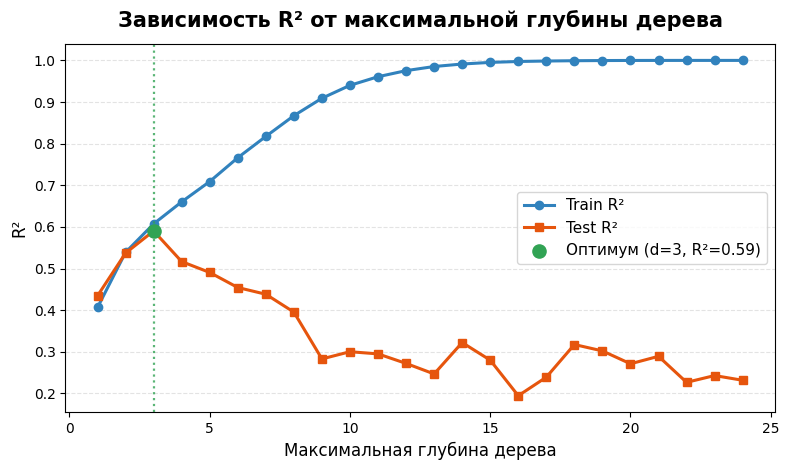

In [29]:
plt.figure(figsize=(8, 4.8))
depths = np.arange(1, 25)

plt.plot(depths, train_scores, label='Train R²', marker='o', linewidth=2.2, color="#3182bd")
plt.plot(depths, test_scores, label='Test R²', marker='s', linewidth=2.2, color="#e6550d")

# Отметим максимум на тесте
best_idx = np.argmax(test_scores)
plt.scatter(depths[best_idx], test_scores[best_idx], color="#31a354", s=90, zorder=5, label=f'Оптимум (d={depths[best_idx]}, R²={test_scores[best_idx]:.2f})')
plt.axvline(depths[best_idx], color="#31a354", linestyle=':', linewidth=1.6, alpha=0.8)

plt.xlabel('Максимальная глубина дерева', fontsize=12)
plt.ylabel('R²', fontsize=12)
plt.title('Зависимость R² от максимальной глубины дерева', fontsize=15, fontweight='bold', pad=12)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [30]:
# Видим на графике лучшую глубину по тесту
best_index = max(range(len(test_scores)), key=lambda i: test_scores[i])
print('Оптимальная max_depth по тесту:', depths[best_index])
print(f'R^2 при оптимальной глубине: {test_scores[best_index]:.3f}')

Оптимальная max_depth по тесту: 3
R^2 при оптимальной глубине: 0.590


График показывает характерную зависимость. С увеличением глубины качество алгоритма дерева на обучающей выборке монотонно растёт до значения 1, когда дерево идеально предсказывает тренировочную выборку. В то же время качество на тестовой выборке сначала растёт, достигая максимума при значениях глубины 3–5, а затем начинает снижаться из-за переобучения.

Это показывает компромисс между смещением и дисперсией (bias-variance tradeoff). Вias-variance tradeoff работает так.

- При малых значениях глубины модель слишком ригидная и дерево недообучено. Это говорит о высоком смещении — модель в среднем даёт неправильные предсказания, что ведёт и к низкому тренировочному, и к низкому тестовому $R^2$.

- При слишком больших глубинах модель переобучается. Это говорит о высокой дисперсии — на трейне при большом `max_depth`, метрика качества близка к идеальной, а на тесте качество страдает.

- Существует некоторое оптимальное значение сложности (`'sweet spot'`), при котором модель лучше всего обобщает с наименьшей ошибкой и наилучшим качеством на тестовых данных. В нашем случае это оптимальное значение колеблется от 3 до 5. Такое значение сложности улучшает качество модели на тестовых данных более чем в два раза: $R^2$ = 0.239 и $R^2$ = 0.533 для деревьев глубиной 24 и 3 соответственно.

Пока мы не перешли к следующей секции, **вопрос**.

Как изменение других гиперпараметров (например, `min_samples_leaf` — минимального числа образцов в листе) влияет на поведение модели? Почему регулирование размера листьев или минимального числа образцов для разбиения — это альтернатива ограничению глубины?

Мы экспериментально установили, что ограничение глубины дерева может значительно повысить обобщающую способность модели. На практике помимо `max_depth` часто настраивают и другие параметры, которые влияют на размер и структуру дерева. Например, минимальное число образцов в листе, минимальное число образцов для разделения узла. В следующем разделе мы автоматизируем подбор оптимальных параметров с `Optuna`.

### Pre-pruning: подбор гиперпараметров

Вручную перебирать комбинации гиперпараметров неудобно, особенно когда их много. Для систематического поиска оптимальных значений иногда используется класс `GridSearchCV` из scikit-learn, который перебирает заданные варианты гиперпараметров и оценивает модель на кросс-валидации. Но `GridSearchCV` плох тем, что он вручную перебирает все комбинации гиперпараметров, что приводит к комбинаторному взрыву.

На практике часто используется `Optuna` — фреймворк для автоматизированного поиска оптимальных гиперпараметров для моделей машинного обучения. Этот фреймворк умнее предыдущего и не требует большого количества ресурсов.

Используем `Optuna` для нахождения оптимальных гиперпараметров.

In [32]:
!pip install optuna --quiet

import optuna
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 8.2 MB/s eta 0:00:00


###Задание 6.1 (0.5 балла)

Используй `Optuna` для подбора оптимальной комбинации гиперпараметров для `DecisionTreeRegressor`. Используй 5-кратную кросс-валидацию (cv=5) и метрику  $R^2$ для оценки. После поиска выведи лучшие значения гиперпараметров и соответствующее качество на кросс-валидации. Для этого ты можешь использовать аттрибуты модели `best_value` и `best_params`.

https://optuna.readthedocs.io/en/stable/

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html

In [34]:
# Функция-цель для Optuna
def objective(trial):

    # Пространство поиска
    params = {

        # 1. Структура/глубина
        "max_depth": trial.suggest_int("max_depth", 2, 25),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 2, 200, log=True),

        # 2. Размер узла/листа
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 100),
        "min_samples_leaf":  trial.suggest_int("min_samples_leaf", 1, 100),

        # 3. Критерий + способ сплита
        "criterion": trial.suggest_categorical(
            "criterion", ["squared_error", "friedman_mse",
                          "absolute_error"]),
        "splitter": trial.suggest_categorical("splitter", ["best", "random"]),

        # 4. Сколько фичей просматривать
        "max_features": trial.suggest_categorical(
            "max_features", [None, "sqrt", "log2"]),

        # 5. Pre-pruning
        "min_impurity_decrease": trial.suggest_float(
            "min_impurity_decrease", 1e-7, 1e-2, log=True)

    }



    ##### Напиши код здесь

    model = DecisionTreeRegressor()

    # 5-кратная кросс-валидация, метрика — R^2

    cv = KFold(n_splits=5, shuffle=True, random_state=20)
    r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2')

    return r2.mean()

# Запускаем исследование (300 trials)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Лучшее значение R^2:", study.best_value)
print("Лучшие гиперпараметры:", study.best_params)

[I 2026-03-17 10:18:46,441] A new study created in memory with name: no-name-487e0842-94f7-476c-a693-36f275a22f8c
[I 2026-03-17 10:18:47,287] Trial 0 finished with value: 0.27280712762021747 and parameters: {'max_depth': 16, 'max_leaf_nodes': 3, 'min_samples_split': 90, 'min_samples_leaf': 36, 'criterion': 'squared_error', 'splitter': 'random', 'max_features': 'sqrt', 'min_impurity_decrease': 0.003764161638745809}. Best is trial 0 with value: 0.27280712762021747.
[I 2026-03-17 10:18:48,137] Trial 1 finished with value: 0.2643834978918613 and parameters: {'max_depth': 5, 'max_leaf_nodes': 4, 'min_samples_split': 43, 'min_samples_leaf': 80, 'criterion': 'friedman_mse', 'splitter': 'random', 'max_features': None, 'min_impurity_decrease': 4.795891184767764e-07}. Best is trial 0 with value: 0.27280712762021747.
[I 2026-03-17 10:18:48,944] Trial 2 finished with value: 0.3023558075015986 and parameters: {'max_depth': 15, 'max_leaf_nodes': 3, 'min_samples_split': 5, 'min_samples_leaf': 63, 'cr

Лучшее значение R^2: 0.31742232593007225
Лучшие гиперпараметры: {'max_depth': 10, 'max_leaf_nodes': 11, 'min_samples_split': 37, 'min_samples_leaf': 26, 'criterion': 'friedman_mse', 'splitter': 'best', 'max_features': 'sqrt', 'min_impurity_decrease': 1.685847586039605e-05}


Изобразим ход оптимизации.

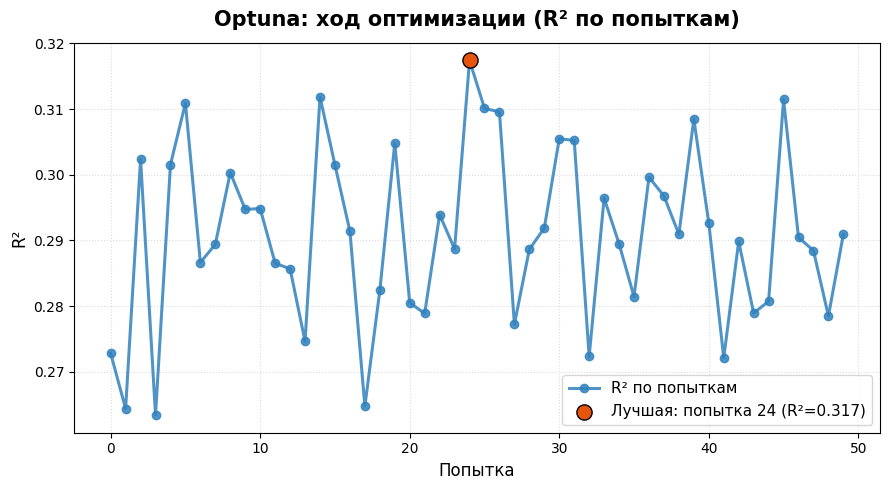

In [35]:
# DataFrame со всеми попытками
df = study.trials_dataframe()

plt.figure(figsize=(9, 5))
plt.plot(df["number"], df["value"], marker='o', color="#3182bd", linewidth=2.2, alpha=0.85, label="R² по попыткам")

# Отметим максимум
best_idx = df["value"].idxmax()
best_trial = df.loc[best_idx, "number"]
best_value = df.loc[best_idx, "value"]

plt.scatter(best_trial, best_value,
            color="#e6550d", s=120, edgecolor='black', zorder=5,
            label=f'Лучшая: попытка {best_trial} (R²={best_value:.3f})')

plt.xlabel("Попытка", fontsize=12)
plt.ylabel("R²", fontsize=12)
plt.title("Optuna: ход оптимизации (R² по попыткам)", fontsize=15, fontweight='bold', pad=12)
plt.grid(True, linestyle=':', alpha=0.45)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [36]:
!pip install optuna[visualization] --quiet

In [37]:
import optuna.visualization as vis
import plotly.io as pio

# Выберем светлую тему для интерактива
pio.templates.default = "plotly_white"

fig = vis.plot_param_importances(
    study,
    target_name="R²",  # Подпись оси
)
# Тюнинг заголовка, шрифта, ширины и цветов
fig.update_layout(
    title={
        "text": "Важность гиперпараметров (Optuna)",
        "x": 0.5,
        "font": {"size": 22, "family": "Arial", "color": "#222"}
    },
    xaxis_title="Вклад в улучшение R²",
    yaxis_title="Гиперпараметр",
    font=dict(size=14, family="Arial"),
    width=800,
    height=500,
    margin=dict(l=80, r=30, t=70, b=60)
)
fig.update_traces(marker_color="#756bb1", marker_line_color='#333', marker_line_width=1.5)
fig.show()

###Задание 6.2 (0.5 балла)

Обучи модель с этими гиперпараметрами на всей обучающей выборке и оцени её $R^2$ на тестовой выборке.

In [38]:
best_params = study.best_params

# Напиши код здесь

# Обучаем дерево на всём train
best_tree = DecisionTreeRegressor(**study.best_params)
best_tree.fit(X_train, y_train)

# Оцениваем на test
y_pred = best_tree.predict(X_test)
r2 = r2_score(y_test, y_pred)

print(f"Test R²:{r2:.3f}")

Test R²:0.549


Мы разобрали один из способов борьбы с переобучением в деревьях решений. Это класс методов pre-pruning, который изначально обучает деревья с ограниченными гиперпараметрами.

Однако этот способ ненадёжен. Pre-pruning принимает решение о разбиении чисто локально (на уровне одного узла) и может остановить рост ещё до того, как дерево поймёт важные взаимодействия между признаками. К тому же пороги приходится подбирать эмпирически, и при малейших изменениях данных модель может заметно меняться.

### Post-pruning: стрижка дерева

Разберём более надёжный и стабильный метод по предотвращению переобучения. Cost-complexity pruning — стрижка полностью обученного дерева. Этот метод относится к классу post-pruning-техник.

Идея в том, чтобы для каждого значения ограничивающего гиперпараметра $\alpha$ найти поддерево $T_\alpha \subseteq T_0$, минимизирующее функцию стоимости $C_\alpha(T)$:

$$C_{\alpha}(T) = \sum_{m=1}^{|T|} |R_m| H_m(T) + \alpha |T|.$$

Мы полностью обучаем дерево, получая верхнюю функцию стоимости с $\alpha=0$ (или просто RSS). Далее мы постепенно начинаем увеличивать $\alpha$. Чтобы минимизировать верхнюю функцию стоимости, дереву приходится «сжиматься»: постепенно сокращать свои «наименее полезные» листовые вершины. По мере увеличения $\alpha$ дерево становится всё короче и в итоге сокращается до просто корня.

Мы перебираем $\alpha$, при котором дерево сокращается, и анализируем качество каждого сокращённого дерева на тестовых данных. В итоге среди всех сокращённых деревьев выбираем дерево с наиболее высоким качеством на тестовых (или валидационных) данных.

Посмотрим, как будет работать cost-complexity pruning на наших данных.

In [39]:
# Определяем все значения альфы, при которых дерево сокращается
base_tree = DecisionTreeRegressor(random_state=42)
path = base_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

# Посмотрим на качество модели для каждого значения альфы
train_r2 = []
test_r2 = []
for alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42, ccp_alpha=alpha)
    model.fit(X_train, y_train)
    train_r2.append(model.score(X_train, y_train))    # R^2 на трейне
    test_r2.append(model.score(X_test, y_test))       # R^2 на тесте

In [40]:
len(ccp_alphas)

1158

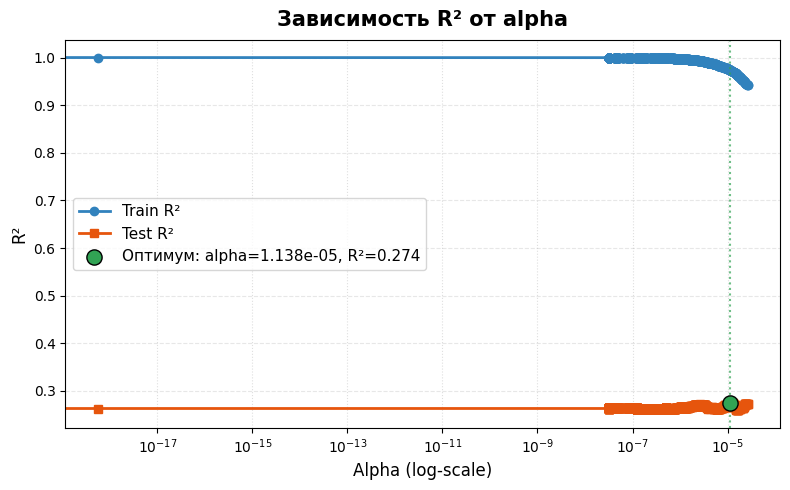

In [41]:
# Нарисуем зависимость качества от гиперпараметра альфа
# Берём индекс 1016, так как после него качество резко падает и на трейне, и на тесте

N = 1016
plt.figure(figsize=(8, 5))

plt.plot(ccp_alphas[:N], train_r2[:N], marker='o', color="#3182bd", linewidth=2, label='Train R²')
plt.plot(ccp_alphas[:N], test_r2[:N], marker='s', color="#e6550d", linewidth=2, label='Test R²')

# Оптимум на тесте
best_idx = np.argmax(test_r2[:N])
best_alpha = ccp_alphas[best_idx]
best_r2 = test_r2[best_idx]
plt.scatter(best_alpha, best_r2, s=120, color="#31a354", edgecolor="black", zorder=5,
            label=f'Оптимум: alpha={best_alpha:.4g}, R²={best_r2:.3f}')
plt.axvline(best_alpha, linestyle=':', color="#31a354", linewidth=1.5, alpha=0.7)

plt.xscale('log')
plt.xlabel('Alpha (log-scale)', fontsize=12)
plt.ylabel('R²', fontsize=12)
plt.title('Зависимость R² от alpha', fontsize=15, fontweight='bold', pad=10)
plt.grid(True, which='both', axis='x', linestyle=':', alpha=0.4)
plt.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [42]:
# Значение альфы, при котором качество на тесте максимально
best_idx = np.argmax(test_r2)
best_alpha = ccp_alphas[best_idx]
print(f"Оптимальное ccp_alpha = {best_alpha:.5f}, R^2 на тесте = {test_r2[best_idx]:.3f}")

Оптимальное ccp_alpha = 0.00053, R^2 на тесте = 0.593


Большая часть значений $\alpha$ меньше 0.0001. Эти значения дают низкое качество на тесте, так как недостаточно сильно обрезают дерево. В итоге переобучение остаётся.

In [43]:
len(ccp_alphas)

1158

In [44]:
largealphas = ccp_alphas[ccp_alphas>0.0001]
largealphas

array([0.00010095, 0.00010113, 0.00010535, 0.0001095 , 0.00011013,
       0.00011188, 0.00011194, 0.00011236, 0.00011325, 0.00011586,
       0.00011785, 0.00012266, 0.00012737, 0.00013278, 0.00013292,
       0.00013338, 0.00014132, 0.00014256, 0.00014609, 0.00014747,
       0.00015339, 0.00015746, 0.00015941, 0.00016223, 0.00016243,
       0.00018503, 0.00018586, 0.00019102, 0.00019125, 0.00019149,
       0.00020459, 0.0002154 , 0.0002256 , 0.00022848, 0.00024464,
       0.00024494, 0.0002528 , 0.00026937, 0.00026985, 0.00027027,
       0.0002908 , 0.00029333, 0.00029568, 0.00031325, 0.00031726,
       0.00032558, 0.0003918 , 0.0004108 , 0.00042844, 0.00043413,
       0.00052692, 0.00052722, 0.00086588, 0.00116673, 0.00143367,
       0.00259888, 0.00455962, 0.02197665])

Здесь мы приходим к тому же выводу, что и в разборе про ограничение глубины. Нужно сильно обрезать дерево (установить высокое $\alpha$), чтобы избежать переобучения.

Проверка качества на тестовой выборке — не самый надёжный способ выбрать оптимальную модель. Лучше провести кросс-валидацию и проверять качество каждого дерева сразу на пяти валидационных выборках.

In [45]:
param_grid = {
    'ccp_alpha': largealphas}

grid = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)
print(grid.best_params_)
print(grid.best_score_)

{'ccp_alpha': np.float64(0.000526920579022538)}
0.544669677749746


А теперь окончательно оценим модель с полученным оптимальным гиперпараметром $\alpha$ на тестовой выборке.

In [46]:
best_tree = grid.best_estimator_
print('R^2 на тесте лучшей модели:', best_tree.score(X_test, y_test))

R^2 на тесте лучшей модели: 0.5928865654776686


## Важность признаков

В деревьях решений важность признаков измеряется через суммарное уменьшение функции неопределённости (в нашем случае — MSE) при разбиениях, в которых участвует данный признак. Для каждого узла дерева вычисляют, насколько упала неопределённость после сплита по этому признаку, учитывают долю объектов, попавших в узел, и складывают такие вклады по всем узлам.

На будущих неделях мы будем изучать ансамблевые методы. В этих методах значения важности усредняют по всем деревьям, что даёт более стабильную оценку вклада каждого признака.

###Задание 7 (0.5 балла)

Используя полученное с помощью post-pruning дерево `best_tree`, выведи важность признаков датасета.
Воспользуйся определённым аттрибутом экземпляра класса `DecisionTreeRegressor` из sklearn.

In [47]:
# Напиши код здесь
importances = best_tree.feature_importances_
feature_names = X.columns
# Получим индексы сортировки по убыванию важности
indices = np.argsort(importances)[::-1]
top_n = 5
top_features = [feature_names[i] for i in indices[:top_n]]
top_importances = [importances[i] for i in indices[:top_n]]
print('Топ-5 признаков по важности:')
for i in range(top_n):
    print(f"{i+1}.{top_features[i]} - importance {top_importances[i]:.4f}")

Топ-5 признаков по важности:
1.PctIlleg - importance 0.6634
2.PctFam2Par - importance 0.1376
3.PctKids2Par - importance 0.0784
4.NumIlleg - importance 0.0433
5.PctBornSameState - importance 0.0352


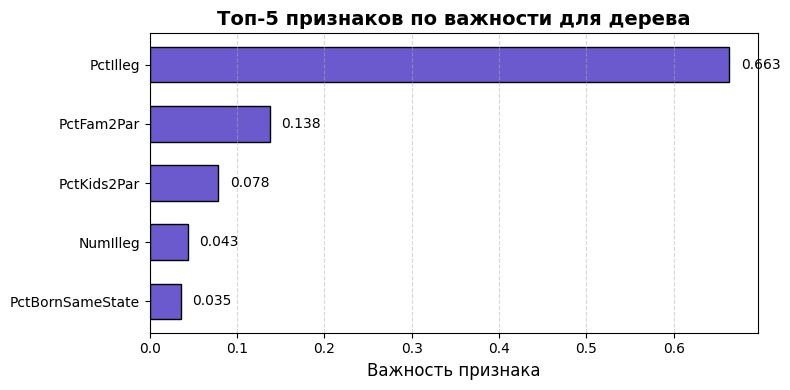

In [48]:
# Нарисуем то, что получили
plt.figure(figsize=(8, 4))
bars = plt.barh(top_features[::-1], top_importances[::-1],
                color='slateblue', edgecolor='black', height=0.6)

# Добавим значения справа от столбцов
for bar in bars:
    width = bar.get_width()
    plt.text(width + max(top_importances)*0.02,
             bar.get_y() + bar.get_height()/2,
             f'{width:.3f}', va='center', fontsize=10)

plt.xlabel('Важность признака', fontsize=12)
plt.title('Топ-5 признаков по важности для дерева', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

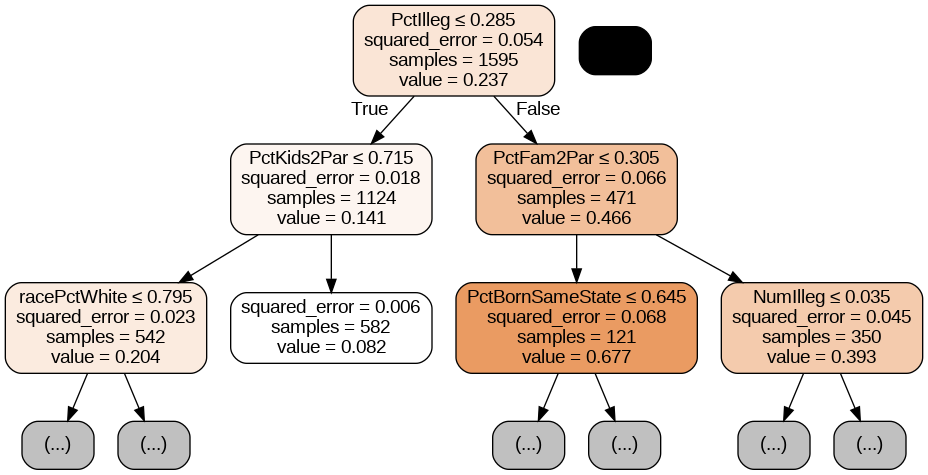

In [49]:
from sklearn.tree import export_graphviz
import pydotplus
from IPython.display import Image

# Посмотрим, как верхняя диаграмма связана с деревом
# Кстати, деревья можно рисовать и с помощью graphviz :)

# Экспортируем дерево в dot-формат
dot_data = export_graphviz(
    best_tree,
    out_file=None,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    special_characters=True,
    max_depth=2,
)

# Строим картинку через pydotplus
graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

# Если появляется чёрный овал рядом с корнем — это баг модуля

<!--Действительно, мы видим, что, чем ближе по разбиению признак находится к корню дерева, тем он важнее. Признак PctKids2Par делится в двух из трёх самых важных узлов дерева, потому он и считается наиболее важным, причём с отрывом от других признаков: деление по этому признаку приводит к наибольшему суммарному уменьшению меры неопределённости (квадратичной ошибки) -->

Чем ближе по разбиению признак находится к корню дерева, тем он важнее. Признак `PctKids2Par` делится в двух из трёх самых важных узлов дерева, потому он и считается наиболее важным среди других признаков.

## Сравнение с линейной регрессией

На лекции мы разбирали, что линейные модели, по сравнению с деревями решений, гораздо более ригидные. Выбор лучшей модели зависит от данных: если наблюдения распределены линейным образом, выбираем линейную модель. Если данные распределены явно нелинейно, выбираем дерево регрессий.

Сгенерируем данные, распределённые синусоидным образом (истинная зависимость — синус), и добавим к ним шум. Посмотрим, какой алгоритм покажет лучший результат на этих данных.

###Задание 8.1 (0.5 балла)

Обучи линейную регрессию и дерево регрессии (глубина = 4) на тренировочных данных.

Используй обученные модели для предсказания значений целевой переменной для всех значений фичи $Х$ от 0 до 5 (это нужно для дальнейшей визуализации предсказания моделей).

После этого рассчитай $R^2$ для обеих моделей на тестовых данных `X_test`, `y_test`.

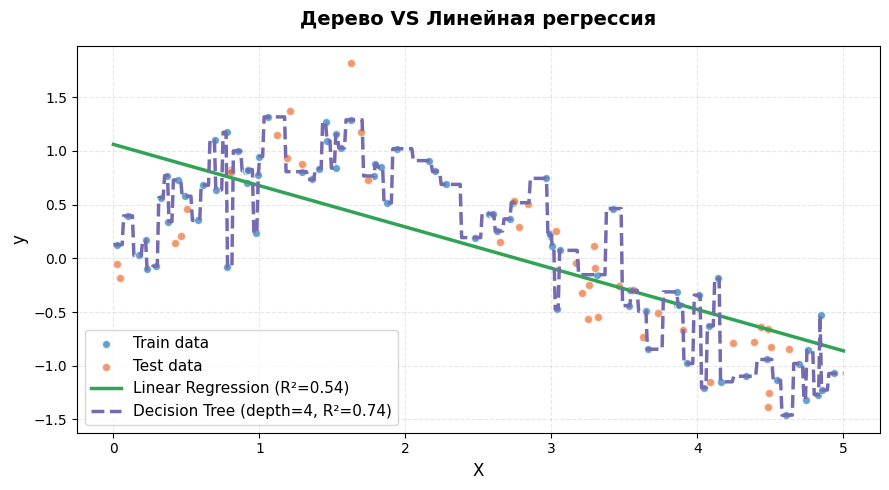

In [50]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1.1) Синтез данных
rng = np.random.RandomState(42)
X_train = np.sort(5 * rng.rand(80, 1), axis=0)
y_train = np.sin(X_train).ravel() + 0.3 * rng.randn(80)

# 1.2) Независимая тест-выборка
X_test = np.sort(5 * rng.rand(40, 1), axis=0)
y_test = np.sin(X_test).ravel() + 0.3 * rng.randn(40)


# Напиши код здесь
# 2) Обучи лин. рег. и дерево регрессии на обучающих данных
lin = LinearRegression()
tree = DecisionTreeRegressor()
lin.fit(X_train, y_train)
tree.fit(X_train, y_train)

# 3) Прогнозы для иксов от 0 до 5
grid = np.linspace(0, 5, 500).reshape(-1, 1)
y_lin_grid = lin.predict(grid)
y_tree_grid = tree.predict(grid)

# 4) R² лин. рег. и дерева на тестовых данных
r2_lin = r2_score(y_test, lin.predict(X_test))
r2_tree = r2_score(y_test, tree.predict(X_test))

# 5) Визуализируем
plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, s=36, color="#3182bd", alpha=0.75,
            edgecolor="white", linewidth=1, label="Train data")
plt.scatter(X_test, y_test, s=36, color="#e6550d", alpha=0.60,
            edgecolor="white", linewidth=1, label="Test data")

plt.plot(grid, y_lin_grid,  color="#31a354", linewidth=2.5, label=f"Linear Regression (R²={r2_lin:.2f})")
plt.plot(grid, y_tree_grid, color="#756bb1", linewidth=2.5, linestyle='--', label=f"Decision Tree (depth=4, R²={r2_tree:.2f})")

plt.xlabel("X", fontsize=12)
plt.ylabel("y", fontsize=12)
plt.title("Дерево VS Линейная регрессия", fontsize=14, fontweight='bold', pad=15)
plt.legend(fontsize=11, frameon=True, loc="lower left")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Данные распределены нелинейно и имеют значительный шум. В таких условиях дерево лучше подстраивается под «изгибы» в наблюдениях и  показывает лучшие результаты.

А теперь посмотрим, как будут себя показывать алгоритмы на данных, распределённых линейно.

###Задание 8.2 (0.5 балла)

Обучи линейную регрессию и дерево регрессии (глубина=2) на тренировочных данных.

Используй обученные модели для предсказания значений целевой переменной для всех значений фичи $Х$ от 0 до 5. Это нужно, чтобы потом визуализировать предсказания моделей.

После этого рассчитай $R^2$ для обеих моделей на тестовых данных `X_test`, `y_test`.

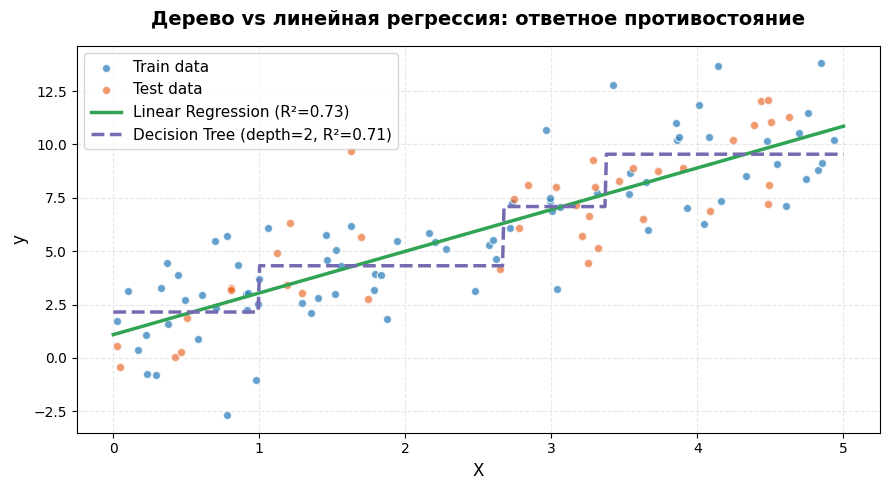

In [51]:
# 1) Cинтетика: почти линейная зависимость y ≈ 2·x + 1 + шум
rng = np.random.RandomState(42)
X_train = np.sort(5 * rng.rand(80, 1), axis=0)
y_train = 2 * X_train.ravel() + 1 + 2 * rng.randn(80)   # σ=2

X_test = np.sort(5 * rng.rand(40, 1), axis=0)
y_test = 2 * X_test.ravel() + 1 + 2 * rng.randn(40)

# Напиши код здесь
# 2) Обучаем модели
lin = LinearRegression()
tree = DecisionTreeRegressor(max_depth=2)
lin.fit(X_train, y_train)
tree.fit(X_train, y_train)

# 3) Прогнозы для иксов от 0 до 5
grid = np.linspace(0, 5, 500).reshape(-1, 1)
y_lin_grid = lin.predict(grid)
y_tree_grid = tree.predict(grid)

# 4) R² на тесте
r2_lin = r2_score(y_test, lin.predict(X_test))
r2_tree = r2_score(y_test, tree.predict(X_test))

# 5) Визуализируем
plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, s=36, color="#3182bd", alpha=0.75,
            edgecolor="white", linewidth=1, label="Train data")
plt.scatter(X_test, y_test, s=36, color="#e6550d", alpha=0.60,
            edgecolor="white", linewidth=1, label="Test data")

plt.plot(grid, y_lin_grid,  color="#31a354", linewidth=2.5, label=f"Linear Regression (R²={r2_lin:.2f})")
plt.plot(grid, y_tree_grid, color="#756bb1", linewidth=2.5, linestyle='--', label=f"Decision Tree (depth=2, R²={r2_tree:.2f})")

plt.xlabel("X", fontsize=12)
plt.ylabel("y", fontsize=12)
plt.title("Дерево vs линейная регрессия: ответное противостояние", fontsize=14, fontweight='bold', pad=15)
plt.legend(fontsize=11, frameon=True, loc="upper left")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Как и ожидалось, в этот раз линейная регрессия показала себя немного лучше.

## Теперь ты умеешь

- Обучать дерево решений, используя sklearn
- Оценивать качество дерева (train/test)
- Визуализировать дерево решений
- Ограничивать и стричь дерево (для борьбы с переобучением)
- Оценивать важность признаков с помощью древесной структуры
